## Load the libraries

In [16]:
import torch 
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.optim as optim
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [17]:
real_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\videos\original_sequences\youtube\c23\videos"
)

fake_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\videos\manipulated_sequences\Deepfakes\c23\videos"
)

real_videos = list(real_dir.glob("*.mp4"))
fake_videos = list(fake_dir.glob("*.mp4"))

print("Real videos:", len(real_videos))
print("Fake videos:", len(fake_videos))

print("\nSample real video:", real_videos[0].name if real_videos else "None")
print("Sample fake video:", fake_videos[0].name if fake_videos else "None")

Real videos: 100
Fake videos: 100

Sample real video: 033.mp4
Sample fake video: 033_097.mp4


Video opened: True
Total frames: 809
FPS: 25.0


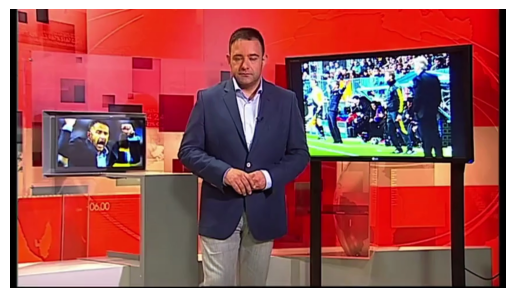

In [18]:
video_path = str(real_videos[0])

cap = cv.VideoCapture(video_path)

print("Video opened:", cap.isOpened())
print("Total frames:", int(cap.get(cv.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv.CAP_PROP_FPS))

ret, frame = cap.read()

if ret:
    frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
    plt.imshow(frame)
    plt.axis("off")
    plt.show()
else:
    print("Could not read a frame.")

cap.release()

In [19]:
def extract_frames(video_path, num_frames=16):
    cap = cv.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames == 0:
        cap.release()
        raise ValueError(f"Cannot read video: {video_path}")

    indices = np.linspace(
        0, total_frames - 1, num_frames, dtype=int
    )

    frames = []

    for idx in indices:
        cap.set(cv.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()

        if ret:
            frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
            frames.append(frame)

    cap.release()

    return frames

sample_frames = extract_frames(real_videos[0])

print("Frames extracted:", len(sample_frames))
print("Frame shape:", sample_frames[0].shape if sample_frames else None)

Frames extracted: 16
Frame shape: (480, 854, 3)


In [20]:
IMG_SIZE = 224

transform = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

frame_tensor = transform(sample_frames[0])

print("Transformed frame shape:", frame_tensor.shape)
print("Data type:", frame_tensor.dtype)

Transformed frame shape: torch.Size([3, 224, 224])
Data type: torch.float32


In [21]:
class DeepfakeVideoDataset(Dataset):
    def __init__(self, real_videos, fake_videos, transform, num_frames=16):
        self.video_paths = (
            [(path, 0) for path in real_videos] +
            [(path, 1) for path in fake_videos]
        )
        self.transform = transform
        self.num_frames = num_frames

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        video_path, label = self.video_paths[idx]

        cap = cv.VideoCapture(str(video_path))
        total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

        if not cap.isOpened() or total_frames == 0:
            cap.release()
            raise RuntimeError(f"Cannot read video: {video_path}")

        indices = np.linspace(
            0, total_frames - 1, self.num_frames, dtype=int
        )

        frames = []

        for frame_idx in indices:
            cap.set(cv.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                cap.release()
                raise RuntimeError(
                    f"Failed to read frame {frame_idx} from {video_path}"
                )

            frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
            frame = self.transform(frame)
            frames.append(frame)

        cap.release()

        frames = torch.stack(frames)

        return frames, torch.tensor(label, dtype=torch.long)

In [22]:
video_dataset = DeepfakeVideoDataset(real_videos, fake_videos, transform)
print("Dataset length:", len(video_dataset))

Dataset length: 200


In [23]:
frames, label = video_dataset[0]
print("Frames shape:", frames.shape)
print("Label:", label)

Frames shape: torch.Size([16, 3, 224, 224])
Label: tensor(0)


In [24]:
real_names = [p.stem for p in real_videos]
fake_names = [p.stem for p in fake_videos]

print("Sample real names:", real_names[:10])
print("Sample fake names:", fake_names[:10])

Sample real names: ['033', '035', '036', '044', '046', '055', '062', '066', '097', '107']
Sample fake names: ['033_097', '035_036', '036_035', '044_945', '046_904', '055_147', '062_066', '066_062', '097_033', '107_109']


In [25]:
real_ids = {p.stem for p in real_videos}
fake_source_ids = set()
for path in fake_videos:
    parts = path.stem.split("_")
    fake_source_ids.update(parts)

print("Unique real source IDs:", len(real_ids))
print("Unique IDs in fake filenames:", len(fake_source_ids))
print("Overlapping IDs:", len(real_ids & fake_source_ids))
print("Sample overlapping IDs:", sorted(real_ids & fake_source_ids)[:20])

Unique real source IDs: 100
Unique IDs in fake filenames: 100
Overlapping IDs: 100
Sample overlapping IDs: ['033', '035', '036', '044', '046', '055', '062', '066', '097', '107', '109', '128', '134', '147', '150', '153', '159', '168', '175', '183']


In [26]:
for real_path in real_videos[:10]:
    source_id = real_path.stem

    matches = [
        p.name for p in fake_videos
        if source_id in p.stem.split("_")
    ]

    print(f"Real: {real_path.name} -> Fake: {matches}")

Real: 033.mp4 -> Fake: ['033_097.mp4', '097_033.mp4']
Real: 035.mp4 -> Fake: ['035_036.mp4', '036_035.mp4']
Real: 036.mp4 -> Fake: ['035_036.mp4', '036_035.mp4']
Real: 044.mp4 -> Fake: ['044_945.mp4', '945_044.mp4']
Real: 046.mp4 -> Fake: ['046_904.mp4', '904_046.mp4']
Real: 055.mp4 -> Fake: ['055_147.mp4', '147_055.mp4']
Real: 062.mp4 -> Fake: ['062_066.mp4', '066_062.mp4']
Real: 066.mp4 -> Fake: ['062_066.mp4', '066_062.mp4']
Real: 097.mp4 -> Fake: ['033_097.mp4', '097_033.mp4']
Real: 107.mp4 -> Fake: ['107_109.mp4', '109_107.mp4']


In [27]:
from collections import defaultdict

# Each source ID is a node.
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# Include every real-video ID.
for path in real_videos:
    find(path.stem)

# Connect the two IDs appearing in each fake filename.
for path in fake_videos:
    ids = path.stem.split("_")

    if len(ids) == 2:
        union(ids[0], ids[1])

# Group real videos by connected component.
groups = defaultdict(list)

for path in real_videos:
    groups[find(path.stem)].append(path.stem)

print("Number of source groups:", len(groups))
print("Sample groups:", list(groups.values())[:10])

Number of source groups: 50
Sample groups: [['033', '097'], ['035', '036'], ['044', '945'], ['046', '904'], ['055', '147'], ['062', '066'], ['107', '109'], ['128', '896'], ['134', '192'], ['150', '153']]


In [28]:
group_list = list(groups.values())

print("Total groups:", len(group_list))
print("Largest group size:", max(len(g) for g in group_list))
print("Group sizes:", sorted([len(g) for g in group_list], reverse=True))

Total groups: 50
Largest group size: 2
Group sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [29]:
import random

random.seed(42)

group_list = list(groups.values())
random.shuffle(group_list)

train_groups = group_list[:35]
val_groups = group_list[35:43]
test_groups = group_list[43:]

print("Train groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

Train groups: 35
Validation groups: 8
Test groups: 7


In [30]:
train_ids = {x for group in train_groups for x in group}
val_ids = {x for group in val_groups for x in group}
test_ids = {x for group in test_groups for x in group}

print("Train source IDs:", len(train_ids))
print("Validation source IDs:", len(val_ids))
print("Test source IDs:", len(test_ids))

print("Train/validation overlap:", len(train_ids & val_ids))
print("Train/test overlap:", len(train_ids & test_ids))
print("Validation/test overlap:", len(val_ids & test_ids))

Train source IDs: 70
Validation source IDs: 16
Test source IDs: 14
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0


In [31]:
def assign_videos(real_videos, fake_videos, source_ids):
    selected = []

    # Add real videos
    for path in real_videos:
        if path.stem in source_ids:
            selected.append((path, 0))

    # Add fake videos only when both source IDs belong to this split
    for path in fake_videos:
        ids = path.stem.split("_")

        if len(ids) == 2 and all(x in source_ids for x in ids):
            selected.append((path, 1))

    return selected


train_samples = assign_videos(real_videos, fake_videos, train_ids)
val_samples = assign_videos(real_videos, fake_videos, val_ids)
test_samples = assign_videos(real_videos, fake_videos, test_ids)


def show_counts(name, samples):
    real_count = sum(label == 0 for _, label in samples)
    fake_count = sum(label == 1 for _, label in samples)

    print(f"{name}: {len(samples)} videos | Real: {real_count} | Fake: {fake_count}")


show_counts("Train", train_samples)
show_counts("Validation", val_samples)
show_counts("Test", test_samples)

Train: 140 videos | Real: 70 | Fake: 70
Validation: 32 videos | Real: 16 | Fake: 16
Test: 28 videos | Real: 14 | Fake: 14


In [32]:
class DeepfakeVideoDatasetFromSamples(Dataset):
    def __init__(self, samples, transform, num_frames=16):
        self.samples = samples
        self.transform = transform
        self.num_frames = num_frames

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_path, label = self.samples[idx]

        frames = extract_frames(video_path, self.num_frames)

        frames = [
            self.transform(frame)
            for frame in frames
        ]

        frames = torch.stack(frames)

        return frames, torch.tensor(label, dtype=torch.long)

In [33]:
train_dataset = DeepfakeVideoDatasetFromSamples(
    train_samples, transform, num_frames=16
)

val_dataset = DeepfakeVideoDatasetFromSamples(
    val_samples, transform, num_frames=16
)

test_dataset = DeepfakeVideoDatasetFromSamples(
    test_samples, transform, num_frames=16
)

In [34]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

frames, label = train_dataset[0]
print("Frames shape:", frames.shape)
print("Label:", label)

140
32
28
Frames shape: torch.Size([16, 3, 224, 224])
Label: tensor(0)


In [35]:
BATCH_SIZE = 2
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [36]:
videos, labels = next(iter(train_loader))

print("Videos shape:", videos.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Videos shape: torch.Size([2, 16, 3, 224, 224])
Labels shape: torch.Size([2])
Labels: tensor([1, 1])


In [37]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [40]:
model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
state_dict = torch.load(r"D:\Projects\Deepfake detection\model\efficientnet_b0_baseline.pth", map_location="cpu", weights_only=True)
model.load_state_dict(state_dict)
print("Model loaded with pre-trained weights.")

Model loaded with pre-trained weights.


In [41]:
cnn = model.features
pool = model.avgpool

cnn = cnn.to(device)
pool = pool.to(device)

cnn.eval()
pool.eval()

print("CNN and pooling layers are set to evaluation mode.")

CNN and pooling layers are set to evaluation mode.


In [42]:
dummy_frame = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
with torch.no_grad():
    features = cnn(dummy_frame)
    pooled_features = pool(features)
    flattened_features = pooled_features.view(pooled_features.size(0), -1)
print("Flattened features shape:", flattened_features.shape)

Flattened features shape: torch.Size([1, 1280])


In [43]:
video_frames, label = next(iter(train_dataset))
video_frames = video_frames.to(device)

with torch.no_grad():
    frame_features = []

    for frame in video_frames:
        frame = frame.unsqueeze(0)  # [1, 3, 224, 224]

        features = cnn(frame)
        features = pool(features)
        features = torch.flatten(features, 1)

        frame_features.append(features.squeeze(0))

    video_features = torch.stack(frame_features)

print("Video feature shape:", video_features.shape)
print("Video label:", label)

Video feature shape: torch.Size([16, 1280])
Video label: tensor(0)


In [62]:
class CNNLSTM(nn.Module):
    def __init__(self, cnn, lstm_hidden_size=256):
        super(CNNLSTM, self).__init__()
        self.cnn = cnn
        self.pool = nn.AdaptiveAvgPool2d((1, 1))    
        self.lstm_hidden_size = lstm_hidden_size
        self.lstm = nn.LSTM(input_size=1280,
                            hidden_size=lstm_hidden_size,
                            batch_first=True)
        self.classifier = nn.Linear(lstm_hidden_size, 1)

    def forward(self, x):
        batch_size, num_frames, C, H, W = x.size()
        frames = x.reshape(batch_size * num_frames, C, H, W)
        features = self.cnn(frames)
        features = self.pool(features)
        features = torch.flatten(features, 1)
        features = features.reshape(batch_size, num_frames, 1280)
        _, (h_n, _) = self.lstm(features)
        output = self.classifier(h_n[-1])
        return output.squeeze(1)


In [63]:
for param in cnn.parameters():
    param.requires_grad = False

In [64]:
video_model = CNNLSTM(cnn).to(device)
print("Video model created successfully!")
print("Device:", next(video_model.parameters()).device)

Video model created successfully!
Device: cuda:0


In [65]:
videos, labels = next(iter(train_loader))
videos = videos.to(device)

video_model.eval()

with torch.no_grad():
    outputs = video_model(videos)

print("Input shape:", videos.shape)
print("Output shape:", outputs.shape)
print("Output scores:", outputs)

Input shape: torch.Size([2, 16, 3, 224, 224])
Output shape: torch.Size([2])
Output scores: tensor([ 0.0267, -0.0386], device='cuda:0')


In [66]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam([
    {'params': video_model.lstm.parameters()},
    {'params': video_model.classifier.parameters()}

], lr=0.001)

In [ ]:
for epoch in range(5):
    video_model.train()
    video_model.cnn.eval()

    total_loss = 0.0
    correct = 0
    total = 0
    for i, (videos, labels) in enumerate(train_loader):
        if i % 10 == 0:
            print(f"Processing batch {i + 1}/{len(train_loader)}")
        videos, labels = videos.to(device), labels.to(device).float()
        optimizer.zero_grad()
        outputs = video_model(videos)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        prediction = (outputs >= 0).long()
        total_loss += loss.item() * videos.size(0)
        correct += (prediction == labels.long()).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch + 1} - Loss: {total_loss / total:.4f}, Accuracy: {correct / total:.4f}")

    video_model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for i, (videos, labels) in enumerate(val_loader):
            if i % 10 == 0:
                print(f"Processing validation batch {i + 1}/{len(val_loader)}")
            videos, labels = videos.to(device), labels.to(device).float()
            outputs = video_model(videos)
            loss = criterion(outputs, labels)
            prediction = (outputs >= 0).long()
            val_loss += loss.item() * videos.size(0)
            correct += (prediction == labels.long()).sum().item()
            total += labels.size(0)

    print(f"Validation - Loss: {val_loss / total:.4f}, Accuracy: {correct / total:.4f}")

Processing batch 1/70
Processing batch 11/70
Processing batch 21/70
Processing batch 31/70
Processing batch 41/70
Processing batch 51/70
Processing batch 61/70
Epoch 1 - Loss: 0.7585, Accuracy: 0.4071
Processing validation batch 1/16
Processing validation batch 11/16
Validation - Loss: 0.6933, Accuracy: 0.5000


In [68]:
from collections import Counter

video_model.eval()

true_labels = []
pred_labels = []

with torch.no_grad():
    for videos, labels in val_loader:
        videos = videos.to(device)

        outputs = video_model(videos)
        predictions = (outputs >= 0).long()

        true_labels.extend(labels.tolist())
        pred_labels.extend(predictions.cpu().tolist())

print("True labels:", Counter(true_labels))
print("Predicted labels:", Counter(pred_labels))

True labels: Counter({0: 16, 1: 16})
Predicted labels: Counter({0: 32})


In [69]:
video_model.eval()

videos, labels = next(iter(val_loader))
videos = videos.to(device)

with torch.no_grad():
    logits = video_model(videos)
    probabilities = torch.sigmoid(logits)

print("Labels:", labels.tolist())
print("Logits:", logits.cpu().tolist())
print("Fake probabilities:", probabilities.cpu().tolist())

Labels: [0, 0]
Logits: [-0.027132483199238777, -0.06391875445842743]
Fake probabilities: [0.4932172894477844, 0.484025776386261]


In [70]:
print(
    "CNN trainable parameters:",
    sum(p.numel() for p in video_model.cnn.parameters()
        if p.requires_grad)
)

print(
    "LSTM trainable parameters:",
    sum(p.numel() for p in video_model.lstm.parameters()
        if p.requires_grad)
)

print(
    "Classifier trainable parameters:",
    sum(p.numel() for p in video_model.classifier.parameters()
        if p.requires_grad)
)

CNN trainable parameters: 0
LSTM trainable parameters: 1574912
Classifier trainable parameters: 257


In [71]:
from collections import Counter

video_model.eval()

true_labels = []
pred_labels = []

with torch.no_grad():
    for videos, labels in train_loader:
        videos = videos.to(device)

        logits = video_model(videos)
        predictions = (logits >= 0).long()

        true_labels.extend(labels.tolist())
        pred_labels.extend(predictions.cpu().tolist())

print("True labels:", Counter(true_labels))
print("Predicted labels:", Counter(pred_labels))

True labels: Counter({0: 70, 1: 70})
Predicted labels: Counter({0: 132, 1: 8})


In [72]:
video_model.eval()

real_logits = []
fake_logits = []

with torch.no_grad():
    for videos, labels in train_loader:
        videos = videos.to(device)
        logits = video_model(videos)

        for i, label in enumerate(labels):
            if label.item() == 0:
                real_logits.append(logits[i].item())
            else:
                fake_logits.append(logits[i].item())

print("Average real logit:", sum(real_logits) / len(real_logits))
print("Average fake logit:", sum(fake_logits) / len(fake_logits))

Average real logit: -0.04637873861938715
Average fake logit: -0.043701612018048765
